# Wnioskowanie statystyczne: od próby do precyzji estymacji

**Workbook uczestnika | studia podyplomowe | 180 minut | Python/Jupyter**

W tym notebooku znajdziesz demonstracje, a potem zadania **do samodzielnego uzupełnienia**. Puste miejsca oznaczono `...`. W każdej sekcji możesz rozwinąć dwie podpowiedzi. Pierwsza mówi, **której funkcji użyć**, druga pomaga dobrać argumenty, ale nie podaje wyniku.

**Plan:** 0–15 intuicja · 15–35 próba · 35–70 CTG (średnia i proporcja) · 70–80 przerwa · 80–110 estymacja punktowa · 110–145 przedziałowa · 145–170 precyzja i n · 170–180 podsumowanie.

**Cel:** umieć samodzielnie obliczyć oszacowanie, SE, przedział ufności, margines błędu i potrzebną liczebność próby. Dane są syntetyczne. Nie testujemy hipotez.

{download}`Pobierz ten workbook jako plik .ipynb <10a-workbook.ipynb>`


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import math

plt.style.use('seaborn-v0_8-whitegrid')
# Dane są syntetyczne. Ziarna pozwalają porównać wyniki w grupie.
pop_rng=np.random.default_rng(2026)
populacja=np.clip(pop_rng.lognormal(2.5,.48,100_000),1,80)
mu_pop=populacja.mean()  # W praktyce tego parametru nie znamy.
print('Środowisko gotowe!')


Środowisko gotowe!


## 0–15 min | Czy 20 zamówień wystarczy?

Firma podaje średni czas realizacji **13 godzin**. Analityk zebrał 20 zamówień i uzyskał **11,8 h**.

W parach: czy to wystarczający dowód poprawy? Jak dobrano próbę? Dlaczego średnia kolejnej próby może być inna?

**Twoja intuicja:** ...

## 15–35 min | Populacja, próba i estymator

**Pokaz:** obserwuj trzy losowania. Która średnia jest najbardziej stabilna i dlaczego?

### Eksperyment interaktywny. Losuj ponownie!

Ustaw suwaki:

- **Liczebność próby** $n$: 10–500 zamówień.
- **Liczba losowań**: 1–100 niezależnych prób.

Kliknij **Losuj ponownie**. Po lewej widzisz wartości z pierwszej próby (niebiesko-zielony histogram), jej średnią (pomarańczowa linia) i prawdziwy parametr (ciemna linia przerywana). Po prawej pojawia się rozkład średnich z wykonanych losowań. Im więcej prób, tym czytelniej widać rozrzut estymatora.

**Zadanie:** pozostaw liczbę losowań 100 i porównaj $n=10$, $50$, $200$. Potem kliknij ponownie przy tym samym $n$. Czy średnie zawsze są takie same?

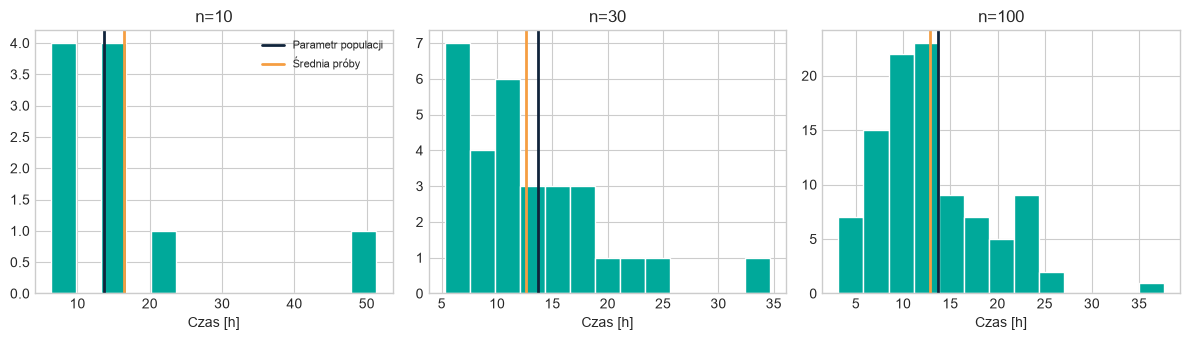

In [ ]:
# DEMONSTRACJA (gotowy kod): ten sam parametr, różne próby
fig,axs=plt.subplots(1,3,figsize=(12,3.5))
for ax,n in zip(axs,[10,30,100]):
    local_rng=np.random.default_rng(100+n)   #to jest ziarno losowania, zakomentuj, zobacz co się stanie...
    x=local_rng.choice(populacja,n,replace=False)
    ax.hist(x,bins=13,color='#00A99A',edgecolor='white')
    ax.axvline(mu_pop,color='#10243B',lw=2,label='Parametr populacji')
    ax.axvline(x.mean(),color='#F59E42',lw=2,label='Średnia próby')
    ax.set(title=f'n={n}',xlabel='Czas [h]')
axs[0].legend(fontsize=8)
plt.tight_layout();plt.show()


### Zadanie 1. Samodzielne losowanie

Wylosuj **60** czasów realizacji. Oblicz ich średnią. Porównaj z parametrem populacji pokazanym w demonstracji. Wnioski zapisz własnymi słowami.

In [30]:
rng_zad1=np.random.default_rng(101)
n=60
proba_1 = ...  # TODO: wylosuj n obserwacji z populacja
srednia_1 = ...  # TODO: średnia z próby
if proba_1 is Ellipsis or srednia_1 is Ellipsis:
    print('Uzupełnij dwa miejsca TODO i uruchom komórkę ponownie.')
else:
    print('Oszacowanie średniej:',round(float(srednia_1),2))


Uzupełnij dwa miejsca TODO i uruchom komórkę ponownie.


<details style="margin:12px 0;border:1px solid #9DCFC8;border-radius:10px;padding:10px;background:#F1FAF8">
<summary style="cursor:pointer;color:#08796F;font-weight:700">💡 Podpowiedź 1 — jakiej funkcji użyć?</summary>

Poszukaj metody **`rng_zad1.choice()`** oraz metody **`.mean()`** obiektu NumPy.
</details>

<details style="margin:12px 0;border:1px solid #F0D5A6;border-radius:10px;padding:10px;background:#FFFAF0">
<summary style="cursor:pointer;color:#9A5900;font-weight:700">🔎 Podpowiedź 2 — argumenty i składnia</summary>

Losowanie: `rng_zad1.choice(populacja, size=n, replace=False)`. Średnia: metoda `.mean()` wywołana na wylosowanej tablicy.
</details>

## 35–70 min | CTG dla średniej i proporcji

**Pokaz 1:** 1500 średnich z prób dla różnych `n`. Zobacz, jak zmienia się rozkład estymatora.

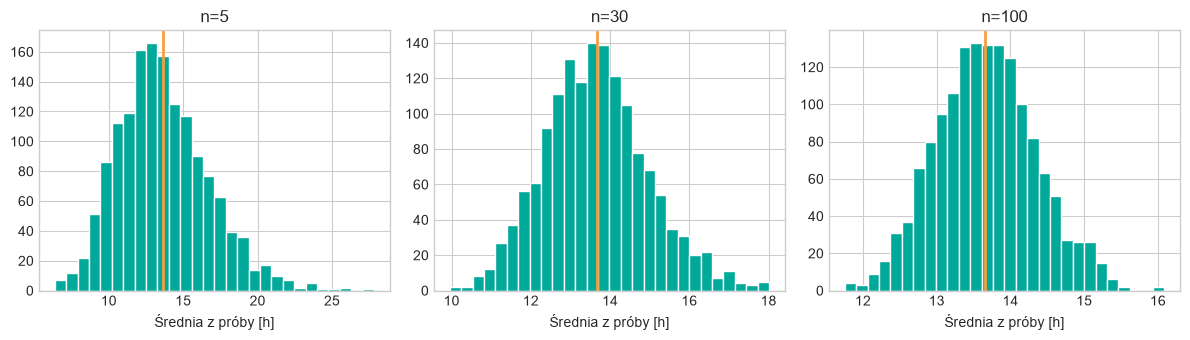

In [40]:
# DEMONSTRACJA: rozkład średnich z wielu prób
fig,axs=plt.subplots(1,3,figsize=(12,3.5))
for ax,n in zip(axs,[5,30,100]):
    local_rng=np.random.default_rng(900+n)   # zakomentuj
    samples=local_rng.choice(populacja,size=(1500,n),replace=True)
    means=samples.mean(axis=1)
    ax.hist(means,bins=28,color='#00A99A',edgecolor='white')
    ax.axvline(mu_pop,color='#F59E42',lw=2)
    ax.set(title=f'n={n}',xlabel='Średnia z próby [h]')
plt.tight_layout();plt.show()


**Pytanie:** dlaczego rozkład średnich może być niemal normalny, mimo że surowe czasy są prawoskośne? Co zmienia czterokrotnie większa próba?

**Pokaz 2:** zmienna binarna `1 = zwrot`, `0 = brak zwrotu`. Proporcja jest średnią z wartości 0/1.

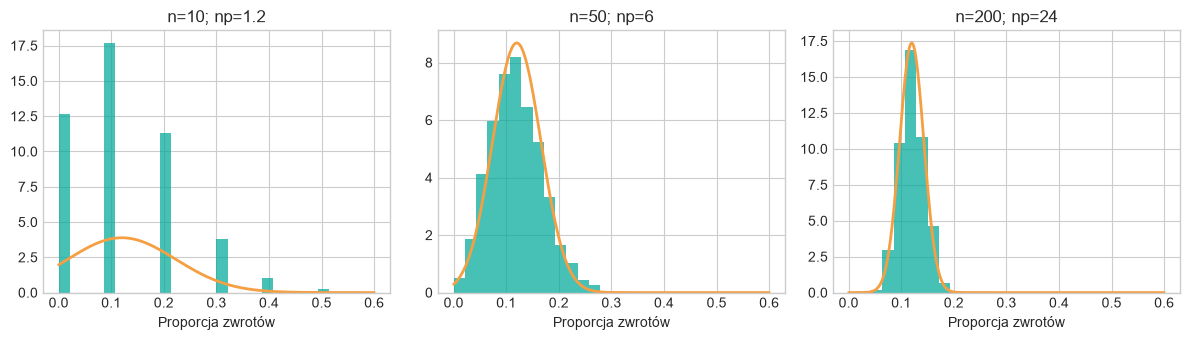

In [ ]:
# DEMONSTRACJA: CTG dla proporcji (0/1)
p=0.12
fig,axs=plt.subplots(1,3,figsize=(12,3.5))
for ax,n in zip(axs,[10,50,200]):
    local_rng=np.random.default_rng(500+n)  #zakomentuj
    counts=local_rng.binomial(n,p,size=2000)
    proportions=counts/n
    ax.hist(proportions,bins=np.linspace(0,.6,29),density=True,
            color='#00A99A',alpha=.72)
    xx=np.linspace(0,.6,350)
    ax.plot(xx,stats.norm.pdf(xx,loc=p,scale=np.sqrt(p*(1-p)/n)),
            color='#F59E42',lw=2)
    ax.set(title=f'n={n}; np={n*p:g}',xlabel='Proporcja zwrotów')
plt.tight_layout();plt.show()


### Zadanie 2. Rozkład proporcji z próbek

Symuluj **1000** prób wielkości **80** przy prawdziwym udziale zwrotów **12%**. Wyznacz 1000 proporcji. Zrób histogram. Porównaj otrzymaną średnią proporcji z 0,12.

In [49]:
p=0.12
n=80
B=1000
rng_zad2=np.random.default_rng(222)
liczby_zwrotow = ...  # TODO: wylosuj B wartości Bin(n,p)
proporcje = ...       # TODO: podziel liczby zwrotów przez n
if liczby_zwrotow is Ellipsis or proporcje is Ellipsis:
    print('Uzupełnij kod symulacji.')
else:
    plt.hist(proporcje,bins=20,color='#00A99A')
    plt.axvline(p,color='#F59E42',label='Parametr populacji')
    plt.legend();plt.show()
    print('Średnia symulowanych proporcji:',round(float(np.mean(proporcje)),3))


Uzupełnij kod symulacji.


<details style="margin:12px 0;border:1px solid #9DCFC8;border-radius:10px;padding:10px;background:#F1FAF8">
<summary style="cursor:pointer;color:#08796F;font-weight:700">💡 Podpowiedź 1 — jakiej funkcji użyć?</summary>

Użyj **`stats.binom.rvs()`** albo **`rng_zad2.binomial()`**. Histogram tworzy **`plt.hist()`**.
</details>

<details style="margin:12px 0;border:1px solid #F0D5A6;border-radius:10px;padding:10px;background:#FFFAF0">
<summary style="cursor:pointer;color:#9A5900;font-weight:700">🔎 Podpowiedź 2 — argumenty i składnia</summary>

SciPy: `stats.binom.rvs(n, p, size=B, random_state=rng_zad2)`. Proporcja w każdej próbie = liczba sukcesów podzielona przez `n`.
</details>

## 70–80 min | Przerwa

## 80–110 min | Estymacja punktowa

Pracujemy na tym samym zbiorze 40 zamówień. Obliczymy: średnią, odchylenie standardowe **z poprawką Bessela (`ddof=1`)**, a potem szacowany błąd standardowy średniej.

In [50]:
# Nasza własna próba do kolejnych zadań.
rng=np.random.default_rng(12345)
czas=rng.choice(populacja,size=40,replace=False)
liczba_reklamacji=48
liczba_dostaw=400
print('Wylosowano',len(czas),'zamówień. Dane:',np.round(czas[:8],1),'...')


Wylosowano 40 zamówień. Dane: [ 6.3  7.7  7.2 17.4 21.  12.9 12.5  5.9] ...


### Zadanie 3. Średnia, odchylenie, błąd standardowy

1. Oblicz średnią `czas`.
2. Oblicz odchylenie standardowe z próby.
3. Oblicz szacowany błąd standardowy **dwoma sposobami**: ze wzoru i gotową funkcją SciPy.

**Uwaga:** SD opisuje zmienność pojedynczych czasów; SE opisuje zmienność średniej z próby.

In [51]:
xbar = ...   # TODO: średnia
s = ...      # TODO: odchylenie standardowe z ddof=1
se_wzor = ...  # TODO: s / pierwiastek z n
se_scipy = ... # TODO: gotowa funkcja scipy.stats
if any(v is Ellipsis for v in (xbar,s,se_wzor,se_scipy)):
    print('Uzupełnij 4 miejsca TODO.')
else:
    print(f'Średnia = {xbar:.2f} h, SD = {s:.2f} h')
    print(f'SE ze wzoru = {se_wzor:.3f} h, SciPy = {se_scipy:.3f} h')


Uzupełnij 4 miejsca TODO.


<details style="margin:12px 0;border:1px solid #9DCFC8;border-radius:10px;padding:10px;background:#F1FAF8">
<summary style="cursor:pointer;color:#08796F;font-weight:700">💡 Podpowiedź 1 — jakiej funkcji użyć?</summary>

NumPy: **`np.mean()`**, **`np.std()`**, **`np.sqrt()`**. SciPy: **`stats.sem()`**.
</details>

<details style="margin:12px 0;border:1px solid #F0D5A6;border-radius:10px;padding:10px;background:#FFFAF0">
<summary style="cursor:pointer;color:#9A5900;font-weight:700">🔎 Podpowiedź 2 — argumenty i składnia</summary>

Odchylenie: `np.std(czas, ddof=1)`. Gotowy błąd standardowy: `stats.sem(czas)`. Porównaj z ilorazem `s / np.sqrt(len(czas))`.
</details>

### Zadanie 4. Estymacja punktowa proporcji

W 400 dostawach stwierdzono 48 reklamacji. Wyznacz udział reklamacji i szacowany błąd standardowy tej proporcji.

In [52]:
p_hat = ...     # TODO: oszacowanie proporcji
se_p = ...      # TODO: szacowany SE proporcji
if p_hat is Ellipsis or se_p is Ellipsis:
    print('Wyznacz p_hat oraz se_p.')
else:
    print(f'Proporcja = {p_hat:.2%}, SE = {se_p:.2%}')


Wyznacz p_hat oraz se_p.


<details style="margin:12px 0;border:1px solid #9DCFC8;border-radius:10px;padding:10px;background:#F1FAF8">
<summary style="cursor:pointer;color:#08796F;font-weight:700">💡 Podpowiedź 1 — jakiej funkcji użyć?</summary>

Użyj działań arytmetycznych oraz **`np.sqrt()`**. Dla proporcji z próby Bernoulliego SE szacujemy z `p_hat`.
</details>

<details style="margin:12px 0;border:1px solid #F0D5A6;border-radius:10px;padding:10px;background:#FFFAF0">
<summary style="cursor:pointer;color:#9A5900;font-weight:700">🔎 Podpowiedź 2 — argumenty i składnia</summary>

Podstaw do `sqrt(p_hat * (1-p_hat) / liczba_dostaw)`; najpierw policz `p_hat = liczba_reklamacji / liczba_dostaw`.
</details>

## 110–145 min | Estymacja przedziałowa i precyzja

**Średnia:** 95% przedział $\bar x\pm t^* s/\sqrt n$. Margines błędu $E=t^*SE$. Precyzja względna to $E/|\bar x|$ (jeśli interpretacja procentowa ma sens).

W Pythonie możesz wyznaczyć kwantyl `t.ppf()` albo użyć gotowego `t.interval()`.

### Zadanie 5. 95% przedział dla średniej czasu

Oblicz przedział na dwa sposoby:

1. Samodzielnie, korzystając z kwantyla $t^*$.
2. Gotową funkcją `scipy.stats`.

Wyznacz margines błędu **w godzinach** oraz **w procentach średniej**.

In [53]:
confidence=.95
df=len(czas)-1
tcrit = ...              # TODO: kwantyl rozkładu t
E = ...                  # TODO: margines błędu
ci_recznie = (..., ...)  # TODO: krańce przedziału
ci_stats = ...           # TODO: gotowy przedział z scipy.stats
E_wzgledny = ...         # TODO: E / |xbar|
if any(v is Ellipsis for v in (tcrit,E,ci_stats,E_wzgledny)) or Ellipsis in ci_recznie:
    print('Uzupełnij wszystkie miejsca TODO.')
else:
    print('CI ręcznie:',ci_recznie,'CI SciPy:',ci_stats)
    print(f'Margines błędu = {E:.2f} h = {E_wzgledny:.1%} średniej')


Uzupełnij wszystkie miejsca TODO.


<details style="margin:12px 0;border:1px solid #9DCFC8;border-radius:10px;padding:10px;background:#F1FAF8">
<summary style="cursor:pointer;color:#08796F;font-weight:700">💡 Podpowiedź 1 — jakiej funkcji użyć?</summary>

Użyj **`stats.t.ppf()`** i **`stats.t.interval()`**. Pierwsza zwraca kwantyl, druga cały przedział.
</details>

<details style="margin:12px 0;border:1px solid #F0D5A6;border-radius:10px;padding:10px;background:#FFFAF0">
<summary style="cursor:pointer;color:#9A5900;font-weight:700">🔎 Podpowiedź 2 — argumenty i składnia</summary>

Kwantyl: `stats.t.ppf((1+confidence)/2, df)`. Przedział: `stats.t.interval(confidence, df=df, loc=xbar, scale=se_scipy)`. Względny margines to `E/abs(xbar)`.
</details>

### Zadanie 6. 95% przedział dla proporcji reklamacji

Tym razem skorzystaj z gotowej metody **Wilsona** w SciPy. Następnie oblicz połowę jego szerokości w **punktach procentowych**.

Uwaga: nazwa funkcji zawiera słowo `binomtest`, ale wykorzystujemy ją tutaj **wyłącznie do obliczenia przedziału ufności**. Nie przeprowadzamy testu hipotezy.

In [54]:
ci_wilson = ...       # TODO: przedział dla jednej proporcji
E_pp = ...             # TODO: połowa szerokości w punktach procentowych
if ci_wilson is Ellipsis or E_pp is Ellipsis:
    print('Wyznacz przedział Wilsona i margines błędu w p.p.')
else:
    print(f'95% CI Wilsona: [{ci_wilson.low:.2%}; {ci_wilson.high:.2%}]')
    print(f'Połowa szerokości: {E_pp:.2f} p.p.')


Wyznacz przedział Wilsona i margines błędu w p.p.


<details style="margin:12px 0;border:1px solid #9DCFC8;border-radius:10px;padding:10px;background:#F1FAF8">
<summary style="cursor:pointer;color:#08796F;font-weight:700">💡 Podpowiedź 1 — jakiej funkcji użyć?</summary>

W SciPy znajdziesz **`stats.binomtest()`** i metodę wyniku **`.proportion_ci()`**.
</details>

<details style="margin:12px 0;border:1px solid #F0D5A6;border-radius:10px;padding:10px;background:#FFFAF0">
<summary style="cursor:pointer;color:#9A5900;font-weight:700">🔎 Podpowiedź 2 — argumenty i składnia</summary>

Utwórz wynik przez `stats.binomtest(liczba_reklamacji, liczba_dostaw)`, następnie użyj `.proportion_ci(confidence_level=.95, method="wilson")`. Obiekt zawiera atrybuty `.low` i `.high`.
</details>

## 145–170 min | Precyzja i minimalna liczebność próby

Chcemy uzyskać margines błędu **nie większy niż ±2 p.p.** przy 95% poziomie ufności. Do projektowania badania wykorzystujemy przybliżony wzór $n\geq z^2p(1-p)/E^2$.

**Uwaga:** planowanie z pilotażowym `p` jest przybliżeniem. Przy braku informacji stosujemy konserwatywnie $p=0{,}5$.

### Zadanie 7. Ile dostaw powinniśmy zbadać?

Wyznacz minimalne `n` dla dwóch wariantów:

- `p` z pilotażu = 12%,
- wariant konserwatywny = 50%.

Zaokrąglij wynik **w górę**. Następnie przygotuj wykres zależności planowanego marginesu błędu od `n` w zakresie 100–2500.

In [ ]:
E_docelowe=.02
zcrit = ...          # TODO: kwantyl N(0,1) dla 95% CI
n_pilot = ...        # TODO: wielkość próby z p=.12, zaokrąglona w górę
n_bezpieczne = ...   # TODO: wielkość próby z p=.50, zaokrąglona w górę
if any(v is Ellipsis for v in (zcrit,n_pilot,n_bezpieczne)):
    print('Uzupełnij wzór na n.')
else:
    print('n z pilotażu:',n_pilot,'; n konserwatywne:',n_bezpieczne)


<details style="margin:12px 0;border:1px solid #9DCFC8;border-radius:10px;padding:10px;background:#F1FAF8">
<summary style="cursor:pointer;color:#08796F;font-weight:700">💡 Podpowiedź 1 — jakiej funkcji użyć?</summary>

SciPy: **`stats.norm.ppf()`**. Do zaokrąglania w górę: **`math.ceil()`**.
</details>

<details style="margin:12px 0;border:1px solid #F0D5A6;border-radius:10px;padding:10px;background:#FFFAF0">
<summary style="cursor:pointer;color:#9A5900;font-weight:700">🔎 Podpowiedź 2 — argumenty i składnia</summary>

Użyj `stats.norm.ppf(.975)`. Wstaw do wzoru `zcrit**2 * p * (1-p) / E_docelowe**2`, a całość przekaż do `math.ceil(...)`.
</details>

In [ ]:
# Wykres zostawiamy do samodzielnego zbudowania.
n_grid=np.arange(100,2501,25)
E_grid = ...  # TODO: margines błędu jako wektor, z p=.12
if E_grid is Ellipsis:
    print('Wyznacz margines błędu dla każdego n w n_grid.')
else:
    plt.plot(n_grid,100*E_grid,color='#00A99A',lw=2)
    plt.axhline(2,color='#F59E42',ls='--',label='±2 p.p.')
    plt.xlabel('Liczebność próby');plt.ylabel('Margines błędu [p.p.]')
    plt.legend();plt.show()


<details style="margin:12px 0;border:1px solid #9DCFC8;border-radius:10px;padding:10px;background:#F1FAF8">
<summary style="cursor:pointer;color:#08796F;font-weight:700">💡 Podpowiedź 1 — jakiej funkcji użyć?</summary>

Przydadzą się **`np.sqrt()`** i **`plt.plot()`**.
</details>

<details style="margin:12px 0;border:1px solid #F0D5A6;border-radius:10px;padding:10px;background:#FFFAF0">
<summary style="cursor:pointer;color:#9A5900;font-weight:700">🔎 Podpowiedź 2 — argumenty i składnia</summary>

Wzór wektorowy: `zcrit * np.sqrt(.12*.88/n_grid)`. Wykres wyświetl po przeliczeniu marginesu na punkty procentowe.
</details>

### Zadanie 8. Ile pomiarów czasu realizacji?

Kierownik chce oszacować średni czas realizacji z dokładnością **±1 godzina** przy 95% ufności. Wykorzystaj `s` z pilotażu. Podaj przybliżone minimalne `n`.

**Pytanie:** dlaczego używamy tutaj przybliżenia normalnego do planowania, mimo że przedział dla średniej może później wykorzystywać rozkład t?

In [ ]:
E_czas=1.0
n_czas = ... # TODO: liczebność według zcrit i s z pilotażu
if n_czas is Ellipsis:
    print('Uzupełnij wzór na liczebność próby dla średniej.')
else:
    print('Planowana liczebność:',n_czas)


<details style="margin:12px 0;border:1px solid #9DCFC8;border-radius:10px;padding:10px;background:#F1FAF8">
<summary style="cursor:pointer;color:#08796F;font-weight:700">💡 Podpowiedź 1 — jakiej funkcji użyć?</summary>

Użyj **`math.ceil()`** oraz znanego już kwantyla **`stats.norm.ppf()`**.
</details>

<details style="margin:12px 0;border:1px solid #F0D5A6;border-radius:10px;padding:10px;background:#FFFAF0">
<summary style="cursor:pointer;color:#9A5900;font-weight:700">🔎 Podpowiedź 2 — argumenty i składnia</summary>

Przybliżony wzór: `n = ceil((zcrit * s / E_czas)**2)`. Pamiętaj, że `s` pochodzi z pilotażu i jest oszacowaniem.
</details>

## 170–180 min | Podsumowanie

Odpowiedz bez uruchamiania kodu:

1. Jaka jest różnica między `s`, `SE` i marginesem błędu `E`?
2. Dlaczego czterokrotne zwiększenie próby zmniejsza margines błędu mniej więcej o połowę?
3. Które funkcje SciPy będą Ci najbardziej przydatne przy estymacji średniej i proporcji?
4. Co trzeba ustalić, zanim obliczymy wymaganą liczebność próby?

**Zasada:** najpierw spróbuj samodzielnie. Podpowiedź 1 wskazuje narzędzie. Podpowiedź 2 pomaga ze składnią. Gotowe rozwiązania ma prowadzący.